## **#Importing necessary libraries for data manipulation**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib . pyplot as plt

### **#Load tables into the notebook**

In [ ]:
orders = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/orders.csv")
products = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/products.csv")
aisles= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/aisles.csv")
departments= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/departments.csv")
orderprodprior= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__prior.csv")
orderprodtrain= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__train.csv")

# **#Construct the continuous analytical variable**

In [ ]:
cadence = orders.groupby('user_id')['days_since_prior_order'].mean().reset_index()

In [ ]:
cadence.rename(columns={'days_since_prior_order': 'avg_days_between_orders'}, inplace=True)

# #Save the dataset to the mandatory path

In [ ]:
cadence.to_csv('/content/drive/MyDrive/project_root/data/processed/cadence.csv', index=False)

#PLOTTING DISTRIBUTION

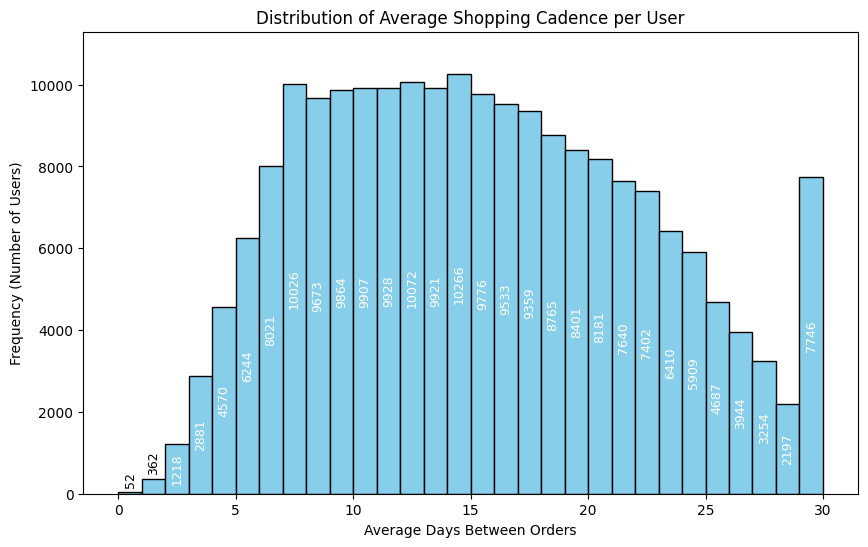

In [ ]:
plt.figure(figsize=(10, 6))
counts, bins, patches = plt.hist(cadence['avg_days_between_orders'], bins=30, edgecolor='black', color='skyblue')

for i, patch in enumerate(patches):
    height = patch.get_height()
    if height == 0: continue

    # First two bars or very small ones: place above. Others: place inside center.
    y_pos = height + (max(counts)*0.01) if i < 2 else height / 2
    va = 'bottom' if i < 2 else 'center'
    color = 'black' if i < 2 else 'white'

    plt.text(patch.get_x() + patch.get_width()/2, y_pos, int(height),
             ha='center', va=va, rotation='vertical', color=color, fontsize=9)

plt.title('Distribution of Average Shopping Cadence per User')
plt.xlabel('Average Days Between Orders')
plt.ylabel('Frequency (Number of Users)')
plt.ylim(0, max(counts) * 1.1)
plt.show()

**#Compute summary statistics**

In [ ]:
# Generates count, mean, std, min, max, and quartiles
summary_stats = cadence['avg_days_between_orders'].describe()

# Calculate specific shape measures
skew_val = cadence['avg_days_between_orders'].skew()
kurt_val = cadence['avg_days_between_orders'].kurt()

print(summary_stats)
print(f"Skewness: {skew_val}")
print(f"Kurtosis: {kurt_val}")


count    206209.000000
mean         15.448686
std           6.915575
min           0.000000
25%           9.814815
50%          15.000000
75%          20.625000
max          30.000000
Name: avg_days_between_orders, dtype: float64
Skewness: 0.24891748031639674
Kurtosis: -0.8044793666773717


Design Sampling Procedure

In [ ]:
sample_results = cadence['avg_days_between_orders'].sample(n=100, random_state=42)
print(f"Sample Mean: {sample_results.mean():.4f}")

Sample Mean: 16.1417


Margin of Error for n=100

Standard Error (SE): First, we calculate SE=σ/
n, which is 6.915575/
100
=0.6915575

Margin of Error (E): We then multiply the Z-score by the Standard Error: 1.96 x 0.6915575

=1.35545

# **#Monte Carlo Simulation**

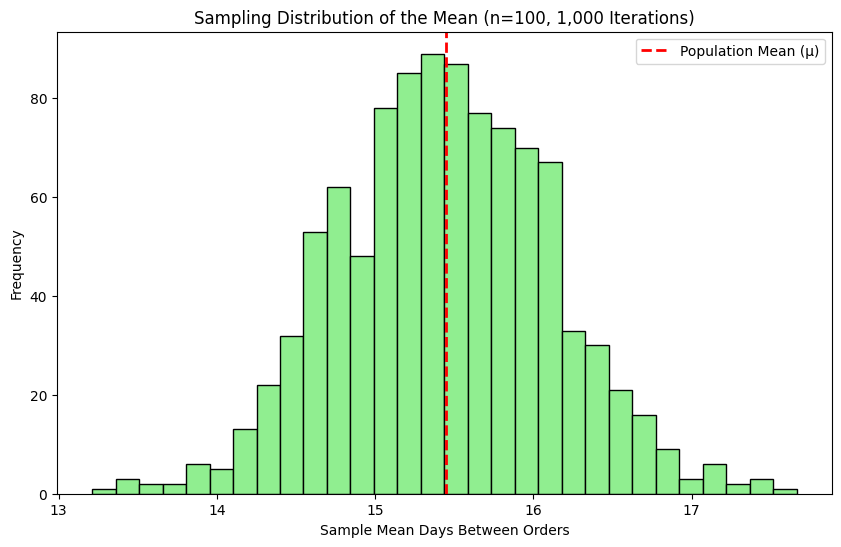

In [ ]:
n = 100
iterations = 1000
simulated_means = []
random_state=42

for i in range(iterations):
    # Using random_state=i ensures the simulation is repeatable/auditable
    sample = cadence['avg_days_between_orders'].sample(n, random_state=i)
    simulated_means.append(sample.mean())

# Convert results into a Series for statistical analysis
sampling_dist = pd.Series(simulated_means)

plt.figure(figsize=(10, 6))
plt.hist(simulated_means, bins=30, edgecolor='black', color='lightgreen')

# Add a vertical line for the true population mean (15.45)
plt.axvline(cadence['avg_days_between_orders'].mean(), color='red', linestyle='dashed', linewidth=2, label='Population Mean (μ)')
plt.title('Sampling Distribution of the Mean (n=100, 1,000 Iterations)')
plt.xlabel('Sample Mean Days Between Orders')
plt.ylabel('Frequency')
plt.legend()

plt.show()

# **#Demonstrating Relationship**

Population Variance (σ to the power 2 ):the standard deviation is 6.915575. Therefore, the variance is 6.915575 to the power 2


 =47.8252

 Sample Size (n): 100


 Theoretical Sampling Variance:  
47.8252/100= 0.4783

# #Standard error and Z score

In [ ]:
# Values from previous steps
pop_mean = 15.45
pop_std = 6.915575
sample_mean = 16.1417
n = 100

# Step 1: Standard Error
se = pop_std / np.sqrt(n)

# Step 2: Z-score
z_score = (sample_mean - pop_mean) / se

print(f"Standard Error: {se:.4f}")
print(f"Z-score: {z_score:.4f}")

Standard Error: 0.6916
Z-score: 1.0002


# **#Confidence Interval**

In [ ]:
# Data from previous steps
sample_mean = 16.1417
pop_std = 6.915575
n = 100
z_crit = 1.96

# Calculate Margin of Error
margin_of_error = z_crit * (pop_std / np.sqrt(n))

# Calculate limits
lower_limit = sample_mean - margin_of_error
upper_limit = sample_mean + margin_of_error

print(f"95% Confidence Interval: [{lower_limit:.4f}, {upper_limit:.4f}]")

95% Confidence Interval: [14.7862, 17.4972]
